<div dir="rtl">

# تحليل مراجعات المقاهي العربية: من المشكلة إلى النتائج

يعرض هذا الدفتر مشروع تعلم الآلة كاملًا بالتسلسل العلمي: **تحديد المشكلة ← جلب البيانات والتحقق منها ← التحليل الاستكشافي ← تجهيز البيانات ← هندسة الخصائص ← منع التسريب ← الـ Pipelines ← خطوط الأساس ← التدريب والتحقق المتقاطع ← اختيار النموذج ← تحليل الأخطاء ← النتائج النهائية.**

**كيف يعمل:** المنطق كله في وحدات المشروع (`src/arabic_reviews/`)، والدفتر يستدعيها ولا ينسخها؛ والوحدة `walkthrough.py` تحوّل السجلات والتقارير إلى جداول ورسوم. كل ما يمكن حسابه من بيانات التطوير **يُعاد حسابه هنا ويُقارن بالتقارير الملتزمة في المستودع**: نتيجة التحقق، والتقسيم، ودرجات CV، والبروتوكول المجمّد، وبصمة النموذج النهائي. كل فحص يطبع سطرًا يبدأ بـ ✓، وأي اختلاف يوقف التشغيل، وسجل الفحوص كلها في آخر الدفتر.

**قواعد ثابتة في هذا الدفتر:**
- **لا يُقيَّم أي نموذج على الاختبار المحجوز (554 مراجعة) هنا، ولا تُقرأ نصوصه بعد التقسيم.** مرحلتا التحقق والتقسيم (القسم 2) تسبقان التقسيم بطبيعتهما، فتعملان على الملف كله كما في الخطوات الأصلية، ولا تُدرِّبان أي نموذج. بعدهما تُحذف البيانات الكاملة من الذاكرة ويُقفل ملف الاختبار لبقية الجلسة، فلا يُستخدم بعد ذلك إلا قسم التطوير. نتائج الاختبار تُعرض من `reports/final_test.json` الذي كتبه التقييم الوحيد (سجل الوصول يحوي قراءة واحدة).
- لا يشغّل الدفتر خطوة `final`، ولا يغيّر البروتوكول المجمّد أو النماذج المحفوظة أو سجل التجارب (`reports/experiments.csv` سجل إلحاقي لا يُكتب فيه هنا).
- تسميات الرسوم إنجليزية لأن matplotlib لا يشكّل الحروف العربية، والجداول بالعربية.

**التشغيل:** بعد تثبيت `requirements-notebook.txt` كما في README: ‏Kernel ← Restart Kernel and Run All Cells. المدة 4–6 دقائق على CPU عادي. في نسخة جديدة من المستودع ينزّل الدفتر ملف البيانات من Zenodo، ويشغّل خطوتي `validate` و`split` إن لم يوجد ملف التطوير المحلي.

**المحتويات:**
0. الإعداد
1. تحديد المشكلة
2. جلب البيانات والتحقق منها
3. التحليل الاستكشافي (التطوير فقط)
4. تجهيز البيانات
5. هندسة الخصائص
6. منع تسريب البيانات
7. الـ Pipelines
8. خطوط الأساس
9. التدريب والتحقق المتقاطع
10. اختيار النموذج وتجميد البروتوكول
11. تحليل الأخطاء (التطوير فقط)
12. النتائج النهائية (من التقارير المحفوظة) والخلاصة

</div>

<div dir="rtl">

## 0. الإعداد

الإصدارات المثبتة مقارنةً بالمسجّلة مع النماذج المحفوظة (`models/model_card.json`)؛ تطابقها شرط لمقارنة بصمة النموذج في القسم 10.

</div>

In [1]:
%matplotlib inline
# vector figures without a creation date, so a re-run reproduces the same outputs
%config InlineBackend.figure_formats = ["svg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "metadata": {"Date": None}}
import pandas as pd
from IPython.display import display

from arabic_reviews import config, experiments, features, protocol, split, validate
from arabic_reviews import walkthrough as wt

wt.setup_display()
wt.environment_table()

,library,installed,recorded_with_models,same
0,python,3.12.12,3.12.12,True
1,scikit-learn,1.8.0,1.8.0,True
2,numpy,2.5.4,2.5.4,True
3,pandas,2.3.3,2.3.3,True
4,joblib,1.6.0,1.6.0,True


<div dir="rtl">

تجهيز البيانات المحلية بخطوات المشروع نفسها: التحقق من ملف المصدر (أو تنزيله)، ثم `validate` و`split` فقط إن غاب ملف التطوير المحلي. هاتان الخطوتان تعيدان كتابة ملفات منشورة، لذلك تُقارن بايتاتها قبل التشغيل وبعده: أي ملف يختلف يُعاد إلى أصله ويتوقف التشغيل. وإن نُزّل الملف، يحتفظ `data/source_manifest.json` بتاريخ الجلب المنشور ما دام كل ما عداه مطابقًا.

</div>

In [2]:
wt.prepare_local_data()

✓ published data manifest, validation and split reports unchanged — byte-identical


,local file,state
0,data/raw/cleaned01_fixed.xlsx,"present; size, MD5 and SHA-256 verified"
1,data/processed/dev.csv,present


<div dir="rtl">

## 1. تحديد المشكلة (Problem Definition)

**السؤال:** من نص مراجعة عربية واحدة لمقهى، ما **الجانب الرئيسي** الذي تتناوله (المأكولات، المشروبات، الخدمة، الجلسات، الاسعار)، وما **قطبية المشاعر** المرتبطة به (ايجابي، سلبي، محايد)؟

**المستخدم ولحظة التنبؤ:** صاحب مقهى أو محلل تجربة عملاء يفرز المراجعات الجديدة عند وصولها. المدخل نص المراجعة وحده، والمخرج وسمان مع مستوى يقين نوعي (عالٍ/متوسط/منخفض) بدل نسبة ثقة خام.

**نوع المسألة:** تصنيفان مستقلان من نص قصير، كلٌّ منهما متعدد الفئات وأحادي الوسم. البيانات تسم كل مراجعة بجانب رئيسي **واحد** ومشاعر مرتبطة به، فلا يدّعي المشروع تحليل كل الجوانب داخل النص (Aspect-Based Sentiment Analysis الكامل). الأمثلة ومعنى الوسوم في `docs/PROBLEM_FRAMING.md`.

**المقياس الأساسي: Macro-F1** لكل مهمة، أي متوسط F1 للفئات بأوزان متساوية. الفئات غير متوازنة (المحايد نحو 9%)، والدقة الكلية تكافئ نموذجًا يتجاهل الفئات النادرة. المقاييس الثانوية: الدقة المتوازنة، والدقة الكلية، والتطابق المشترك (الوسمان صحيحان معًا).

**قرارات أُعلنت قبل أي تجربة** (`PROJECT_PLAN.md` §1.1)، وهي مكتوبة في الكود كما يعرضها الجدول:

</div>

In [3]:
wt.predeclared_settings()

,setting,value
0,sentiment labels,ايجابي / سلبي / محايد
1,aspect labels,المأكولات / المشروبات / الخدمة / الجلسات / الاسعار
2,primary metric,"Macro-F1 per task (fixed label list, zero_division=0)"
3,secondary metrics,"balanced accuracy, accuracy, joint accuracy (both labels right)"
4,selection CV,"3 x 5 grouped stratified folds, seeds (42, 43, 44)"
5,acceptance rule,mean paired gain >= 0.01 and a gain in >= 11 of 15 folds
6,baselines,"dummy_most_frequent, dummy_stratified, logreg_word11"
7,expected test range,"fresh CV seeds (100, 101, 102), never used for a choice"
8,test intervals,"95% percentile bootstrap, 2000 resamples, near-duplicate groups as unit"
9,success on the test,beat both dummies (paired interval > 0) and not below the reference


<div dir="rtl">

فائدة الإعلان المسبق أن كل قرار لاحق (قبول خاصية، اختيار نموذج، الحكم على الاختبار) يُتخذ بقاعدة ثابتة، لا بعد رؤية النتائج.

</div>

<div dir="rtl">

## 2. جلب البيانات والتحقق منها (Data Ingestion & Validation)

**المصدر:** Hmood Al-Dossari, *Multi-Aspect Sentiment Analysis of Arabic Café Reviews Using Machine and Deep Learning Approaches*، Zenodo 2025، الإصدار 1، الملف `cleaned01_fixed.xlsx` (3000 مراجعة لمقاهي الرياض من Google Maps)، ترخيص CC-BY-4.0، ‏DOI: ‏10.5281/zenodo.17781916. البيانات لا تُرفع إلى المستودع؛ خطوة `ingest` تنزّل الملف وتتحقق من حجمه وبصمتيه (MD5 المعلن في Zenodo، وSHA-256) قبل أي استخدام.

### 2.1 بصمة ملف المصدر

</div>

In [4]:
wt.source_fingerprint()

✓ source file matches the published fingerprint — 10.5281/zenodo.17781916


,field,published,local,same
0,size_bytes,125720,125720,True
1,md5,9b546b96eb7d16a374f648b4dc840d59,9b546b96eb7d16a374f648b4dc840d59,True
2,sha256,f171ef057abcae5946106534c8ef26cc9ef32a9d94fb8ec3e1843898f8f6d901,f171ef057abcae5946106534c8ef26cc9ef32a9d94fb8ec3e1843898f8f6d901,True


<div dir="rtl">

### 2.2 المخطط (Schema) والعيوب الفعلية في الملف

يُفحص المخطط أولًا: الأعمدة الثلاثة موجودة، و3000 صف، ولا قيم فارغة، والوسوم من المفردات المعروفة فقط (`validate.check_schema` يرفع خطأً عند أي مخالفة). بعد ذلك تظهر عيوب خاصة بهذا الملف، والجدول يعرض أقصر مثال حقيقي لكل منها قبل الإصلاح وبعده (⏎ سطر جديد، و⟨U+…⟩ محرف غير مرئي):

- **وسوم ملتصقة بنهاية النص** (أثر دمج ملفات CSV). لو بقيت لكانت **تسريبًا مباشرًا للوسم إلى الخصائص**: يتعلم النموذج قراءة الإجابة المكتوبة في النص.
- **ترجمات آلية** أضافتها المنصة في فقرات لاتينية منفصلة.
- **محارف غير مرئية** (علامات اتجاه وغيرها) ومسافات زائدة.

</div>

In [5]:
raw = wt.read_source()
validate.check_schema(raw)
print(f"schema ok: {len(raw)} rows, columns {list(config.RAW_COLUMNS)}")
wt.repair_examples(raw)

schema ok: 3000 rows, columns ['Review', 'Attribute', 'Result']


,step,rows_changed,rid,before,after
0,strip_label_suffix,511,1751,⏎الموظفين سيئين;الخدمة;سلبي,⏎الموظفين سيئين
1,strip_translation,122,514,نعم اجمل خدمه⏎⏎⏎Ok,نعم اجمل خدمه
2,clean_whitespace,962,1126,فلات وايت⟨U+2066⟩❤️⟨U+2069⟩,فلات وايت❤️


<div dir="rtl">

### 2.3 الإصلاح المحافظ وسجل النسب (Lineage)

يُسجَّل لكل خطوة عدد الصفوف قبلها وبعدها، والمعدَّل منها والمستبعد. التنظيف محافظ عمدًا: لا تُحذف هنا أدوات النفي ولا الرموز التعبيرية ولا الأرقام، لأن أثرها على النموذج يُقاس في التجارب ولا يُفترض. المكررات (بمفتاح مطبَّع) تُختزل إلى نسخة واحدة بوسم الأغلبية لكل مهمة، وتُستبعد المجموعات التي تتعادل وسومها.

</div>

In [6]:
validation = validate.run_validation(raw)
validated = validation.data
wt.lineage_table(validation)

,name,reason,rows_before,rows_modified,rows_excluded,rows_after
step,,,,,,
1,strip_label_suffix,label strings glued to the end of the text (CSV-merge artefact),3000,511,0,3000
2,strip_translation,platform translation marker and Latin-only leading/trailing paragraphs,3000,122,0,3000
3,clean_whitespace,"invisible/control characters, repeated spaces, blank lines",3000,962,0,3000
4,exclude_no_arabic,empty or no Arabic letters after repair,3000,0,0,3000
5,deduplicate,one representative per duplicate group; labels by per-task majority,3000,2,217,2783
6,deduplicate_ties,duplicate groups whose labels tie in a task,2783,0,14,2769


In [7]:
wt.verify_validation(validation)
wt.quality_table(validation)

✓ validation reconciles — 3000 = 2769 kept + 231 excluded
✓ validation steps equal the published lineage — reports/lineage.json
✓ validated data byte-identical to the published hash — SHA-256 66b938be391f…


,raw,validated
rows with,,
embedded_label_suffix,511,0
delimiter_label_scan,511,0
translation_marker,9,0
latin_letters,145,24
no_arabic_letters,0,0
invisible_characters,11,0
control_characters,0,0
diacritics,187,171
tatweel,10,10


<div dir="rtl">

**القراءة:** من 3000 إلى 2769 مراجعة، باستبعاد 217 نسخة مكررة و14 صفًا من مجموعات تعادلت وسومها. من الوسوم الملتصقة (511 نصًا) خالف 26 الوسم الرسمي، فعوملت على أنها ضوضاء وسوم وبقي الوسم الرسمي. بعد الإصلاح لم يبقَ أي وسم ملتصق (`embedded_label_suffix`: 0). بصمة البيانات المتحقق منها هنا تساوي المنشورة في `reports/lineage.json`، فالخطوة قابلة للإعادة بايتًا ببايت.

### 2.4 التقسيم أولًا، ثم قفل الاختبار

قبل أي تحليل موجّه أو نمذجة تُقسم البيانات: 80% للتطوير و20% اختبار محجوز، مع إبقاء كل مجموعة مراجعات شبه مكررة في جانب واحد. التجميع والتقسيم يعملان على البيانات المتحقق منها كلها، كما في الخطوة الأصلية: التجميع لا يستخدم الوسوم، والتقسيم يستخدم الوسم المشترك للطبقية فقط. هنا يُعاد بناء التقسيم ويُقارن بالملف المنشور، ولا يُحفظ منه إلا جداول مجمّعة (أحجام المجموعات، وعدّادات التسريب، ونسب الفئات) تُناقش في القسم 6.

</div>

In [8]:
split_result = split.make_split(validated)
split_audit = wt.split_audit(validated, split_result)

✓ split rebuilt from the validated data equals the published split — data/splits/split_v1.csv
✓ near-duplicate pairs equal the published list — 176 pairs


✓ leakage checks are all zero — 14 counts


<div dir="rtl">

**بعد التقسيم:** تُحذف البيانات الكاملة من الذاكرة، ويُقفل ملف الاختبار المحلي حتى إعادة تشغيل الـ kernel. أي محاولة لفتحه تُرفض عبر audit hook في Python: بـ `open` أو pandas أو `pathlib` أو `os.open`، وبمسار نسبي أو مطلق أو رابط إلى الملف. هذا حاجز احترازي من القراءة العرضية، لا عزل كامل. من هنا يُقرأ التطوير وحده بـ `split.load_dev()`، ويُقارن كل صف منه بملف التقسيم المنشور.

</div>

In [9]:
del raw, validation, validated, split_result
wt.lock_test_partition()
dev = split.load_dev()
wt.partition_overview(dev)

locked: data/processed/test.csv cannot be opened again in this session
✓ the development data is exactly the published development partition — 2215 rows: rid, group and CV folds equal to data/splits/split_v1.csv


,rows,groups,share
partition,,,
dev,2215,2090,0.8
test,554,521,0.2


<div dir="rtl">

## 3. التحليل الاستكشافي (EDA): على التطوير فقط

الهدف فهم توزيع الوسوم وطبيعة النص لصياغة فرضيات تختبرها التجارب لاحقًا، دون أي نظر في الاختبار. الأرقام هنا تطابق `reports/eda.md`.

### 3.1 توزيع الوسوم

</div>

sentiment,ايجابي,سلبي,محايد,total
aspect,,,,
المأكولات,251,47,38,336
المشروبات,548,105,49,702
الخدمة,216,240,56,512
الجلسات,291,83,36,410
الاسعار,111,120,24,255
total,1417,595,203,2215


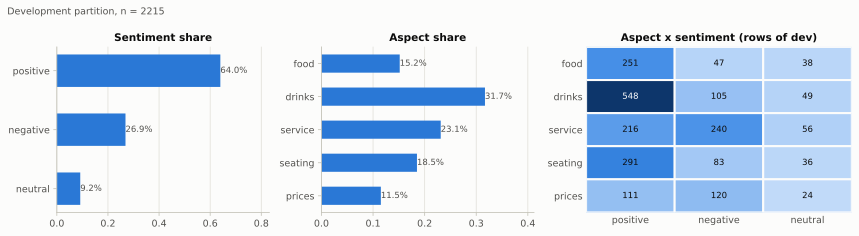

In [10]:
display(wt.label_counts(dev))
wt.plot_labels(dev);

<div dir="rtl">

**القراءة:** الإيجابي نحو 64% والمحايد نحو 9%. لذلك المقياس Macro-F1، وموازنة أوزان الفئات أحد محاور التجارب. الجانب والمشاعر مترابطان: الإيجابي أغلبية في المأكولات والمشروبات والجلسات، والسلبي أكبر فئة في الخدمة والأسعار دون أن يكون أغلبية. مع ذلك يبقيان نموذجين مستقلين، ويُقاس التطابق المشترك مقياسًا ثانويًا.

### 3.2 طول المراجعات

</div>

,rows,words median,words p90,chars median,<= 3 words
sentiment,,,,,
ايجابي,1417,5.0,12.0,27.0,0.253
سلبي,595,8.0,24.0,43.0,0.133
محايد,203,8.0,19.8,41.0,0.094


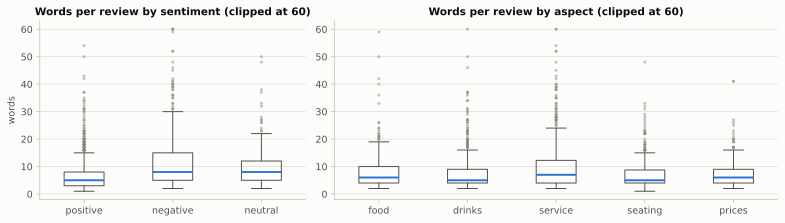

In [11]:
display(wt.length_table(dev))
wt.plot_lengths(dev);

<div dir="rtl">

**القراءة:** المراجعات قصيرة جدًا (الوسيط 5 كلمات للإيجابي و8 للسلبي والمحايد)، ونحو خُمسها 3 كلمات أو أقل. السلبي والمحايد أطول، فالطول مرشح كخاصية بسيطة للمشاعر، ويُقبل فقط إن اجتاز قاعدة القبول (المحور 5).

### 3.3 النفي والرموز التعبيرية

</div>

In [12]:
wt.signal_rates(dev)

,% with a negation particle,% without counting ما,% with an emoji
sentiment,,,
ايجابي,8.6,6.2,6.9
سلبي,33.3,26.4,3.5
محايد,28.1,21.7,4.4


<div dir="rtl">

**القراءة:** أداة نفي تظهر في ثلث المراجعات السلبية تقريبًا مقابل 8.6% من الإيجابية، فالنفي يحمل إشارة ويجب ألا يحذفه التجهيز. العمود الثاني يستبعد «ما» لأن لها استعمالات غير نافية (ما شاء الله). الرموز التعبيرية تميل إلى الإيجابي، فتُترك في النص افتراضيًا.

### 3.4 أكثر العبارات تمييزًا لكل فئة (χ²، فئة مقابل البقية)

</div>

In [13]:
wt.distinctive_terms(dev)

terms
task      label                                                       
sentiment ايجابي                   ممتاز، رائع، جميل، قهوه، مكان، احلي
          سلبي                       غير، مبالغ، للاسف، سيئ، سيئه، سيء
          محايد                    بس، جيد، عادي، لاكن، ممتاز بس، ولكن
aspect    المأكولات  الدونات، دونات، كروسان، والدونات، والكوكيز، لذيذه
          المشروبات       القهوه، قهوه، قهوتهم، المشروبات، موكا، لاتيه
          الخدمة         خدمه، الخدمه، الموظفين، الطلب، زحمه، السيارات
          الجلسات            مكان، المكان، جلسات، الجلسات، هادئ، مريحه
          الاسعار      الاسعار، اسعار، اسعاره، مبالغ، غالي، مبالغ فيها

<div dir="rtl">

**القراءة:** دلائل الجانب لفظية واضحة، لكنها تتوزع على أشكال كتابية متعددة للكلمة نفسها (قهوه/القهوه/قهوتهم، دونات/والدونات، اسعار/الاسعار/اسعاره). هذه الملاحظة هي فرضية المحور الأول: مقاطع الأحرف تجمع الدليل عبر هذه الأشكال. عبارات المحايد استدراكية أو فاترة (بس، عادي، ولكن، مقبول).

### 3.5 كم مراجعة تذكر أكثر من جانب؟

</div>

In [14]:
wt.multi_aspect(dev)

,measure,value
0,0 aspect cue(s),378
1,1 aspect cue(s),1605
2,2 aspect cue(s),219
3,3+ aspect cues,13
4,reviews with cues for >= 2 aspects,10.5%
5,labelled aspect among the cued ones (multi-cue reviews),96.1%
6,single cue agrees with the label (sanity check),94.8%


<div dir="rtl">

**القراءة:** بقائمة جذوع لفظية يدوية لكل جانب، تحمل نحو 10% من المراجعات دلائل لجانبين أو أكثر. هذا تقدير تقريبي لا قياس، لكنه يبيّن أن قيد «جانب واحد لكل مراجعة» سيفسر جزءًا من أخطاء الجانب (يُعد في القسم 11).

</div>

<div dir="rtl">

## 4. تجهيز البيانات (Data Preparation)

يفصل المشروع بين طبقتين:

1. **إصلاح البيانات** (`validate.py`، القسم 2): يعالج عيوب هذا الملف مرة واحدة قبل التقسيم، وكل تعديل مسجَّل في lineage.
2. **تطبيع النص داخل النموذج** (`text.py`): خيارات صريحة، كلها مطفأة افتراضيًا، تُطبَّق داخل الـ Pipeline بالدالة نفسها في التدريب والاستدلال. لا يُفترض أي خيار منها؛ كلٌّ منها مرشح في محاور التجارب 2–4.

الجدول يطبّق كل خيار وحده على أمثلة مصاغة للتوضيح (ليست من البيانات):

</div>

In [15]:
wt.normalisation_table()

original,القهوةةة لذيييذة جداً 😍😍,ما عجبني الأكل، كان بارد!!,سعر الكوب ١٨ ريال والخدمة ممتــازة,الجلسات في الدور الثاني مو مريحة
light (LIGHT),القهوة لذيذة جدا 😍😍,ما عجبني الأكل، كان بارد!!,سعر الكوب ١٨ ريال والخدمة ممتازة,الجلسات في الدور الثاني مو مريحة
full (+ unify letters),القهوه لذيذه جدا 😍😍,ما عجبني الاكل، كان بارد!!,سعر الكوب ١٨ ريال والخدمه ممتازه,الجلسات في الدور الثاني مو مريحه
symbols separate,القهوةةة لذيييذة جداً 😍 😍,ما عجبني الأكل ، كان بارد ! !,سعر الكوب ١٨ ريال والخدمة ممتــازة,الجلسات في الدور الثاني مو مريحة
digits token,القهوةةة لذيييذة جداً 😍😍,ما عجبني الأكل، كان بارد!!,سعر الكوب <NUM> ريال والخدمة ممتــازة,الجلسات في الدور الثاني مو مريحة
negation marked,القهوةةة لذيييذة جداً 😍😍,ما NEG_عجبني الأكل، كان بارد!!,سعر الكوب ١٨ ريال والخدمة ممتــازة,الجلسات في الدور الثاني مو NEG_مريحة
stopwords removed,القهوةةة لذيييذة جداً 😍😍,ما عجبني الأكل، بارد!!,سعر الكوب ١٨ ريال والخدمة ممتــازة,الجلسات الدور الثاني مو مريحة


<div dir="rtl">

**القراءة:**
- `LIGHT` يزيل التشكيل والتطويل والتكرار المطوِّل (لذيييذة ← لذيذة)، و`FULL` يوحّد الهمزات والتاء المربوطة والألف المقصورة.
- أدوات النفي لا تُحذف في أي خيار؛ وسم النفي يضيف `NEG_` إلى الكلمة التالية للأداة، وقائمة كلمات التوقف لا تحوي أي أداة نفي.
- في التجارب (القسم 9) لم يجتز أيٌّ من هذه الخيارات قاعدة القبول (أكبر مكسب +0.0046)، فالنماذج النهائية تعمل على النص بعد الإصلاح فقط (`normalisation: none`). التفسير المرجح أن مقاطع الأحرف تمتص كثيرًا من تنوع الإملاء بنفسها.

</div>

<div dir="rtl">

## 5. هندسة الخصائص (Feature Engineering)

التمثيلات المرشحة كلها TF-IDF، وتُتعلَّم المفردات والأوزان داخل طية التدريب:
- `word11`: كلمات مفردة. `word12`: كلمات وثنائيات كلمات.
- `char25`: مقاطع أحرف بطول 2–5 داخل حدود الكلمة (`char_wb`).
- `word11+char25`: اتحاد التمثيلين (`FeatureUnion`).
- إضافات مرشحة: إحصاءات سطحية للنص (الطول، علامات التعجب والاستفهام، الرموز، أدوات النفي)، ووسم النفي.

**لماذا مقاطع الأحرف؟** العربية تلصق أداة التعريف وحروف العطف والجر والضمائر بالكلمة، وتتنوع كتابتها (ة/ه). فتصبح «قهوه» و«القهوه» و«قهوتهم» ثلاث كلمات لا يجمعها تمثيل الكلمات، بينما تشترك في مقاطع أحرف. الجدول يقيس ذلك بمحلل الأحرف الذي يستخدمه النموذج نفسه:

</div>

In [16]:
wt.char_ngram_overlap([("قهوه", "القهوه"), ("قهوه", "قهوتهم"), ("دونات", "والدونات")])

,pair,shared_word_tokens,shared_char_ngrams,jaccard_char,longest_shared
0,قهوه / القهوه,0,10,0.38,قهوه، قهو، هوه
1,قهوه / قهوتهم,0,6,0.20,قهو
2,دونات / والدونات,0,14,0.41,دونات، دونا، ونات


<div dir="rtl">

حجم فضاء الخصائص لكل تمثيل. هذا وصف فقط: الحساب هنا على التطوير كله لبيان الحجم، أما النماذج فتتعلم مفرداتها داخل كل طية تدريب:

</div>

In [17]:
wt.representation_sizes(dev)

,features,nonzero_per_review
representation,,
word11,5584,7.7
word12,18684,14.6
char25,33850,119.8
word11+char25,39434,127.5


<div dir="rtl">

**القراءة:** مقاطع الأحرف تعطي فضاءً أكبر بنحو ستة أضعاف، وكل مراجعة تفعّل نحو 120 خاصية بدل 8 تقريبًا. هذا يجمع الدليل عبر الأشكال الكتابية، ويرفع خطر الإفراط في الملاءمة، فيضبطه التنظيم (C) في القسم 10. أي التمثيلات فاز؟ يُحسم بالتحقق المتقاطع في القسم 9.

</div>

<div dir="rtl">

## 6. منع تسريب البيانات (Leakage Prevention)

التسريب يعني أن يصل إلى النموذج، أثناء التدريب أو الاختيار، معلومة لن تتوفر عند التنبؤ الحقيقي، فتأتي التقديرات متفائلة. مصادره المحتملة في هذه المسألة وما فُعل لكل منها:

| المصدر | الإجراء |
|---|---|
| وسوم ملتصقة بنص المراجعة | أُزيلت في الإصلاح قبل أي نمذجة (القسم 2) |
| مكررات ونسخ معدّلة تقع في التطوير والاختبار معًا | إزالة المكررات، ثم تجميع شبه المكررات بقواعد لا تقرأ الوسوم، ثم تقسيم بالمجموعات (`StratifiedGroupKFold`) |
| تعلّم المفردات وأوزان IDF من بيانات التقييم | كل `fit` داخل `sklearn.Pipeline` على طيات التدريب فقط (القسم 7) |
| الاختيار بناءً على الاختبار | الاختبار يمر عبر إجراء واحد بعد تجميد البروتوكول ببصمة، وكل قراءة مسجّلة |
| كثرة المقارنات على الطيات نفسها | قاعدة قبول معلنة مسبقًا، ومدى متوقع يُحسب ببذور CV جديدة لم تُستخدم في أي اختيار |

### 6.1 أحجام المجموعات وفحوص التسريب

أُعيد بناء التقسيم في القسم 2.4 وطابق الملف المنشور، وهذه جداوله المجمّعة. أولًا أحجام مجموعات شبه المكررات. ثم عدّادات التسريب، وكلها يجب أن تكون صفرًا: مجموعات، أو مفاتيح نصية مطبّعة، أو أزواج شبه مكررة تعبر بين التطوير والاختبار، أو بين طيات أي تكرار من CV. وأخيرًا توازن نسب الفئات بين القسمين:

</div>

In [18]:
display(split_audit["groups"])
display(split_audit["leakage"])
split_audit["proportions"]

rows in group,1,2,3,4,5,6,9
groups,2499,87,12,10,1,1,1
rows,2499,174,36,40,5,6,9


,count
partition: groups in >1 part,0
partition: bare keys in >1 part,0
partition: near-duplicate pairs across parts,0
cv_fold_r0: groups in >1 part,0
cv_fold_r0: bare keys in >1 part,0
cv_fold_r0: near-duplicate pairs across parts,0
cv_fold_r1: groups in >1 part,0
cv_fold_r1: bare keys in >1 part,0
cv_fold_r1: near-duplicate pairs across parts,0
cv_fold_r2: groups in >1 part,0


,task,label,dev_pct,test_pct,diff_pp
0,aspect,المأكولات,15.17,14.98,0.19
1,aspect,المشروبات,31.69,31.95,0.26
2,aspect,الخدمة,23.12,22.92,0.19
3,aspect,الجلسات,18.51,18.59,0.08
4,aspect,الاسعار,11.51,11.55,0.04
5,sentiment,ايجابي,63.97,63.90,0.07
6,sentiment,سلبي,26.86,26.71,0.15
7,sentiment,محايد,9.16,9.39,0.22


<div dir="rtl">

**القراءة:** 176 زوجًا مرتبطًا كوّنت 112 مجموعة متعددة الصفوف (270 صفًا)، وكل الفحوص صفر، وأكبر فرق في نسب الفئات 0.26 نقطة مئوية. **حدود معروفة** (`reports/split.md`): عائلات القوالب القصيرة مربوطة جزئيًا فقط، والنسخ التي لا تلتقطها أي قاعدة لا يمكن استبعادها دون قراءة نصوص الاختبار، وهو ما لم يُفعل. الفحوص إذن تغطي ما تلتقطه القواعد، لا كل نسخة محتملة.

### 6.2 قفل الاختبار وسجل الوصول

محاولة متعمدة لقراءة ملف الاختبار تُرفض، لأن القفل مفعّل منذ القسم 2.4. ثم سجل الوصول الذي كتبه إجراء التقييم الوحيد:

</div>

In [19]:
try:
    pd.read_csv(config.TEST_FILE)
except PermissionError as err:
    print("refused:", err)
wt.access_log_table()

refused: test.csv is the locked held-out test file; its results are shown from the saved reports only
✓ the held-out test was read exactly once — 1 entry in reports/test_access_log.json


,run,time,commit,test_rows,reason,fingerprint
0,1,2026-10-25T10:29:29+00:00,b577bb0,554,None,ec20dc6ba81703194ac2b536f51698cb75d38427d44fa04f6d2f6401a7977b41


<div dir="rtl">

قُرئ الاختبار مرة واحدة في 2026-10-25، بعد تجميد البروتوكول وبالبصمة نفسها، ولم يُعد فتحه بعد ذلك.

</div>

<div dir="rtl">

## 7. الـ Pipelines

لكل مهمة Pipeline واحدة تجمع: تطبيع النص (`Normalizer`) ← تمثيل TF-IDF ← المصنف. الكائن نفسه يُدرَّب داخل كل طية، ويُحفظ كاملًا بـ joblib، وتستدعيه الواجهة وسطر الأوامر. لا يُكتب أي تحويل مرتين، فلا فرق بين معالجة التدريب ومعالجة الاستدلال (training/serving skew). هذه هي الإعدادات النهائية المجمّدة في `reports/protocol.json`:

</div>

In [20]:
frozen = wt.frozen_specs()
for task, spec in frozen["final"].items():
    print(f"{task}: {spec['name']}")
    print(features.build_pipeline(spec))
    print()

sentiment: m4_logreg_C0.3
Pipeline(steps=[('normalize', Normalizer()),
                ('features',
                 FeatureUnion(transformer_list=[('word11', TfidfVectorizer()),
                                                ('char25',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 ngram_range=(2,
                                                                              5)))])),
                ('clf',
                 LogisticRegression(C=0.3, class_weight='balanced',
                                    max_iter=2000, random_state=0))])

aspect: m4_logreg_C1
Pipeline(steps=[('normalize', Normalizer()),
                ('features',
                 TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5))),
                ('clf',
                 LogisticRegression(C=1, class_weight='balanced', max_iter=2000,
                                    random_state=0))])



<div dir="rtl">

### 7.1 كل `fit` داخل الطية

برهان عملي: تُدرَّب Pipeline المشاعر النهائية على طيات التدريب في أول طية من أول تكرار، ثم تُعدّ مقاطع الطية المحجوزة التي لم ترها المفردات قط.

</div>

In [21]:
wt.in_fold_vocabulary(dev, frozen["final"]["sentiment"], "sentiment")

,train_rows,valid_rows,learned_vocabulary,idf_weights,valid_ngrams,unseen_in_training,unseen_share
vectorizer,,,,,,,
word11,1771,444,4809,4809,1745,775,0.444
char25,1771,444,30125,30125,13548,3725,0.275


<div dir="rtl">

**القراءة:** المفردات وأوزان IDF (عددها يساوي حجم المفردات) تعلّمتها الـ Pipeline من 1771 مراجعة تدريب فقط. 44% من كلمات الطية المحجوزة و27% من مقاطع أحرفها لم ترها المفردات، فتُعامل كمجهولة، تمامًا كما ستُعامل مراجعة جديدة عند الاستدلال. لو بُني الـ vectorizer على البيانات كلها قبل CV لدخلت هذه المقاطع وأوزانها من بيانات التقييم، ولخرجت الدرجات متفائلة.

</div>

<div dir="rtl">

## 8. خطوط الأساس (Baselines)

ثلاثة مراجع أُعلنت قبل التجارب، وكل نموذج لاحق يُقارن بها على الطيات نفسها:
- **Dummy (الأكثر تكرارًا):** يتنبأ دائمًا بفئة الأغلبية. Macro-F1 له يساوي F1 الأغلبية مقسومًا على عدد الفئات.
- **Dummy (طبقي):** يتنبأ عشوائيًا بنسب الفئات. هذا هو مستوى «الصدفة المطلعة على التوزيع».
- **المرجع:** كلمات مفردة TF-IDF مع Logistic Regression بالإعدادات الافتراضية (C = 1، بلا أوزان فئات). أبسط نموذج نصي معقول، وأي تعقيد يجب أن يتفوق عليه.

الدرجات من سجل التجارب (متوسط 15 طية):

</div>

In [22]:
wt.baseline_table()

model  cv_macro_f1      sd  balanced_accuracy  accuracy
task      configuration                                                                             
sentiment dummy_most_frequent  dummy_most_frequent       0.2601  0.0003             0.3333    0.6397
          dummy_stratified        dummy_stratified       0.3479  0.0239             0.3478    0.5044
          logreg_word11                     logreg       0.5236  0.0285             0.5154    0.7604
aspect    dummy_most_frequent  dummy_most_frequent       0.0963  0.0005             0.2000    0.3169
          dummy_stratified        dummy_stratified       0.2016  0.0242             0.2029    0.2251
          logreg_word11                     logreg       0.7923  0.0157             0.7629    0.8009

<div dir="rtl">

إعادة تشغيل CV للمرجع الآن، ومقارنة الطيات الخمس عشرة بالسجل:

</div>

In [23]:
wt.rerun_cv(dev, [(task, spec) for task, spec in frozen["reference"].items()])

✓ sentiment: CV of logreg_word11 reproduces the logged 15 fold scores — largest difference 4.3e-07


✓ aspect: CV of logreg_word11 reproduces the logged 15 fold scores — largest difference 4.7e-07


,,logged_mean,rerun_mean,largest_fold_difference,fit_seconds
task,configuration,,,,
sentiment,logreg_word11,0.5236,0.5236,4.2504e-07,2.5
aspect,logreg_word11,0.7923,0.7923,4.7124e-07,4.1


<div dir="rtl">

**القراءة:** نموذج «الأغلبية» يبلغ دقة 64% في المشاعر وMacro-F1 قدره 0.26 فقط، وهذا مثال عملي على سبب اختيار Macro-F1. المرجع يرفع Macro-F1 إلى 0.52 للمشاعر و0.79 للجانب. إعادة التشغيل تعطي درجات الطيات نفسها المسجلة (الفرق من تقريب السجل إلى 6 منازل فقط).

</div>

<div dir="rtl">

## 9. التدريب والتحقق المتقاطع (Model Training & Cross-Validation)

**التصميم:** 3 تكرارات × 5 طيات مجمّعة وطبقية داخل التطوير (بذور 42–44، أعمدة `cv_fold_r*` في ملف التقسيم المنشور). كل إعداد يحصل على 15 درجة على طيات متطابقة، فتكون المقارنة بين إعدادين **مزدوجة (paired)**: على الطية نفسها، والفرق يُحسب طية بطية.

**هندسة الخصائص بمحاور مرتبة مسبقًا:** (1) التمثيل، (2) التطبيع الإملائي، (3) الرموز والأرقام، (4) وسم النفي وكلمات التوقف، (5) إحصاءات النص، (6) موازنة أوزان الفئات. كل مرشح هو الفائز الحالي مع تغيير واحد، ويُقبل فقط إن رفع المتوسط بـ 0.01 على الأقل **وفاز في 11 طية من 15 على الأقل**. كل تجربة سطر في `reports/experiments.csv`؛ الجداول التالية تُقرأ منه، والقرارات يعيد حسابها الكود.

### 9.1 نتائج المحاور

</div>

In [24]:
ablations = {task: wt.ablation_table(task) for task in experiments.TASKS}
for task, table in ablations.items():
    print(task)
    display(table.round(4))

sentiment


,axis,candidate,against,mean_gain,folds_won,decision
0,Axis 1 - representation,logreg_word12,logreg_word11,-0.0381,0,rejected
1,Axis 1 - representation,logreg_char25,logreg_word11,0.0263,11,accepted
2,Axis 1 - representation,logreg_word11+char25,logreg_char25,0.0507,13,accepted
3,Axis 2 - normalisation,a2_light,logreg_word11+char25,0.0020,7,rejected
4,Axis 2 - normalisation,a2_full,logreg_word11+char25,0.0046,10,rejected
5,Axis 3 - symbols and digits,a3_symbols_separate,logreg_word11+char25,0.0003,5,rejected
6,Axis 3 - symbols and digits,a3_symbols_remove,logreg_word11+char25,0.0005,7,rejected
7,Axis 3 - symbols and digits,a3_digits_token,logreg_word11+char25,0.0019,9,rejected
8,Axis 4 - negation and stopwords,a4_negation,logreg_word11+char25,0.0044,10,rejected
9,Axis 4 - negation and stopwords,a4_stopwords,logreg_word11+char25,-0.0067,6,rejected


aspect


,axis,candidate,against,mean_gain,folds_won,decision
0,Axis 1 - representation,logreg_word12,logreg_word11,-0.0327,0,rejected
1,Axis 1 - representation,logreg_char25,logreg_word11,0.0992,15,accepted
2,Axis 1 - representation,logreg_word11+char25,logreg_char25,-0.0010,7,rejected
3,Axis 2 - normalisation,a2_light,logreg_char25,0.0005,8,rejected
4,Axis 2 - normalisation,a2_full,logreg_char25,0.0029,11,rejected
5,Axis 3 - symbols and digits,a3_symbols_separate,logreg_char25,-0.0003,4,rejected
6,Axis 3 - symbols and digits,a3_symbols_remove,logreg_char25,0.0003,6,rejected
7,Axis 3 - symbols and digits,a3_digits_token,logreg_char25,-0.0010,7,rejected
8,Axis 4 - negation and stopwords,a4_negation,logreg_char25,0.0005,10,rejected
9,Axis 4 - negation and stopwords,a4_stopwords,logreg_char25,0.0005,7,rejected


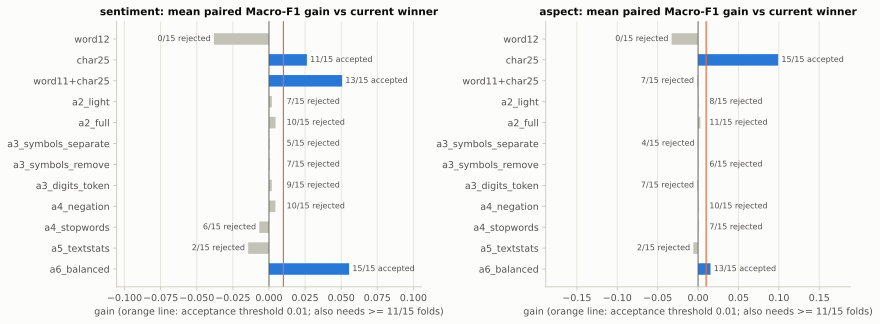

In [25]:
wt.plot_ablation(ablations);

<div dir="rtl">

**القراءة:**
- **التمثيل (المحور 1):** مقاطع الأحرف هي المكسب الأكبر للجانب (+0.099، فوز في 15 طية من 15)، فهي تجمع أشكال الكلمة الواحدة. للمشاعر فاز الاتحاد كلمات+أحرف (+0.051، 13/15). ثنائيات الكلمات خسرت في المهمتين، والتفسير المرجح أن النصوص قصيرة فتتشتت الثنائيات.
- **المحاور 2–5 مرفوضة كلها:** التطبيع ووسم النفي اقتربا من الحد في عدد الطيات (10–11 من 15)، لكن متوسط مكسبهما أقل كثيرًا من 0.01. الرفض هنا لا يعني أنها بلا أثر، بل أن أثرها لم يبلغ العتبة المعلنة.
- **موازنة الأوزان (المحور 6):** مقبولة في المهمتين، وأكبر أثرها في المشاعر (+0.056، 15/15)، لأنها ترفع وزن المحايد والسلبي النادرين في دالة الخسارة.

### 9.2 درجات الطيات على مسار القرار

كل خط رمادي يصل الطية نفسها عبر الإعدادات، فيُرى هل التحسن ثابت عبر الطيات أم مدفوع بطيات قليلة:

</div>

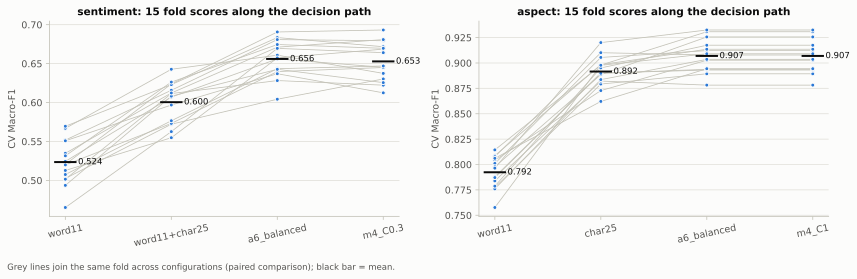

In [26]:
wt.plot_decision_path();

<div dir="rtl">

**القراءة:** على هذا المسار، الانتقال من المرجع إلى التمثيل الفائز يرفع الطيات الخمس عشرة كلها في المهمتين. في المشاعر تم ذلك عبر خطوتين قُبلتا بـ 11/15 ثم 13/15، وفي الجانب بخطوة واحدة 15/15. وموازنة الأوزان ترفع 15/15 في المشاعر و13/15 في الجانب. التحسن إذن ثابت عبر الطيات، لا في متوسطها فقط. الخطوة الأخيرة في المشاعر (C = 0.3) لا ترفع الدرجة (−0.003، 6/15)؛ اختيرت في القسم 10 بقاعدة الخطأ المعياري الواحد لأنها أبسط وضمن الضجيج. وفي الجانب، `m4_logreg_C1` هو `a6_balanced` نفسه بعد قرار الضبط، فدرجاتهما متطابقة. الانحراف المعياري بين الطيات (0.016–0.024) أكبر من كثير من المكاسب المرفوضة، وهذا ما تحمي منه قاعدة الفوز في 11 طية.

</div>

<div dir="rtl">

## 10. اختيار النموذج وتجميد البروتوكول (Model Selection)

بعد تثبيت الخصائص تأتي ثلاث مراحل، بقاعدة القبول نفسها:
1. **عائلات أخرى** بإعداداتها الافتراضية: Linear SVM وComplement Naive Bayes.
2. **ضبط محدود لقوة التنظيم C** على شبكة من 5 قيم، بقاعدة الخطأ المعياري الواحد (one-standard-error rule): تُختار أبسط قيمة (أقوى تنظيمًا) يقع متوسطها ضمن خطأ معياري واحد من الأفضل. وأي قيمة أضعف تنظيمًا من الافتراضي (C = 1) تُعد تعقيدًا إضافيًا، فيجب أن تجتاز قاعدة القبول أيضًا.
3. **خياران لـ TF-IDF:** `min_df=2` و`sublinear_tf`.

</div>

In [27]:
selection = {task: wt.model_selection(task) for task in experiments.TASKS}
display(pd.DataFrame([s["summary"] for s in selection.values()]).set_index("task"))
for task, s in selection.items():
    print(task)
    display(s["table"].round(4))

,family,param,one_se_pick,used,complexity_gate,final
task,,,,,,
sentiment,logreg,C,0.3,0.3,not needed,m4_logreg_C0.3
aspect,logreg,C,3.0,1.0,"+0.0032, 10/15 -> rejected",m4_logreg_C1


sentiment


,stage,candidate,against,mean_gain,folds_won,decision
0,family,m4_linsvm,a6_balanced,-0.0217,2,rejected
1,family,m4_cnb,a6_balanced,-0.1707,0,rejected
2,tf-idf option,m4_logreg_C0.3+min_df2,m4_logreg_C0.3,-0.0057,5,rejected
3,tf-idf option,m4_logreg_C0.3+sublinear,m4_logreg_C0.3,0.0000,9,rejected


aspect


,stage,candidate,against,mean_gain,folds_won,decision
0,family,m4_linsvm,a6_balanced,0.0070,11,rejected
1,family,m4_cnb,a6_balanced,-0.0063,5,rejected
2,tf-idf option,m4_logreg_C1+min_df2,m4_logreg_C1,0.0020,12,rejected
3,tf-idf option,m4_logreg_C1+sublinear,m4_logreg_C1,0.0028,10,rejected


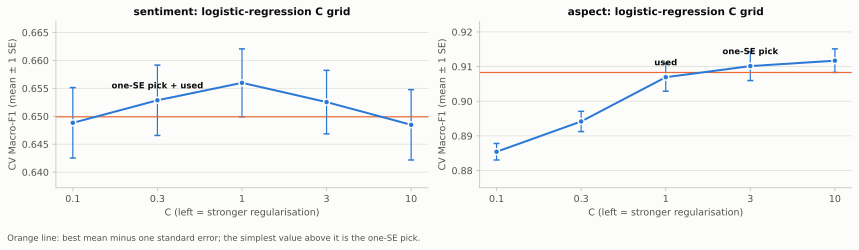

In [28]:
wt.plot_c_grid(selection);

<div dir="rtl">

**القراءة:**
- العائلتان مرفوضتان. Linear SVM في الجانب فاز في 11 طية لكن بمكسب +0.007، أي دون العتبة؛ وComplement NB أضعف بوضوح في المشاعر.
- **المشاعر:** قاعدة الخطأ المعياري الواحد اختارت C = 0.3، وهي أقوى تنظيمًا من الافتراضي فلا تحتاج فحصًا إضافيًا.
- **الجانب:** القاعدة اختارت C = 3، لكنها أضعف تنظيمًا فاختُبرت كتعقيد: +0.0032 في 10 طيات من 15، فلم تجتز القاعدة وبقي C = 1. القاعدة أُعلنت قبل تشغيل الشبكة ولم تُعدَّل بعده.
- خيارا TF-IDF مرفوضان في المهمتين، فمكاسبهما ضمن الضجيج.

### 10.1 إعادة درجات CV للإعدادين النهائيين

</div>

In [29]:
wt.rerun_cv(dev, [(task, spec) for task, spec in frozen["final"].items()])

✓ sentiment: CV of m4_logreg_C0.3 reproduces the logged 15 fold scores — largest difference 4.5e-07


✓ aspect: CV of m4_logreg_C1 reproduces the logged 15 fold scores — largest difference 4.9e-07


,,logged_mean,rerun_mean,largest_fold_difference,fit_seconds
task,configuration,,,,
sentiment,m4_logreg_C0.3,0.6529,0.6529,4.4953e-07,13.2
aspect,m4_logreg_C1,0.9069,0.9069,4.8634e-07,20.0


<div dir="rtl">

### 10.2 تجميد البروتوكول قبل الاختبار

قبل فتح الاختبار جُمِّد كل ما يعتمد عليه: الإعدادات بكل معاملات الـ Pipeline، وعتبات مستويات اليقين (من تنبؤات خارج الطية)، والمدى المتوقع لدرجة الاختبار (من 3 تكرارات CV ببذور جديدة 100–102 لم تُستخدم في أي اختيار)، وخطة الـ bootstrap، وبصمات البيانات، وإصدارات المكتبات. من كل ذلك تُحسب بصمة SHA-256 واحدة.

الخلية التالية تعيد بناء البروتوكول من الكود وبيانات التطوير وحدها (نحو دقيقة ونصف)، وتقارنه بالمجمّد. هذه هي المقارنة نفسها التي يجريها `final --check` قبل بناء النماذج:

</div>

In [30]:
rebuilt = wt.rebuild_protocol(dev)
wt.frozen_configurations(rebuilt)

✓ protocol rebuilt from code and development data equals the frozen protocol — fingerprint ec20dc6ba8170319… = frozen


configuration   model              features normalisation class_weight      params      cv_macro_f1
task      role                                                                                                           
sentiment final      m4_logreg_C0.3  logreg  word11+char25 TF-IDF          none     balanced  {"C": 0.3}  0.6529 ± 0.0244
          reference   logreg_word11  logreg         word11 TF-IDF          none         None          {}  0.5236 ± 0.0285
aspect    final        m4_logreg_C1  logreg         char25 TF-IDF          none     balanced    {"C": 1}  0.9069 ± 0.0157
          reference   logreg_word11  logreg         word11 TF-IDF          none         None          {}  0.7923 ± 0.0157

In [31]:
display(wt.expected_ranges(rebuilt))
wt.certainty_levels(rebuilt)

configuration    mean      sd     low    high
task      role                                                          
sentiment final           m4_logreg_C0.3  0.6564  0.0248  0.6069  0.7060
          reference        logreg_word11  0.5316  0.0271  0.4775  0.5858
aspect    final             m4_logreg_C1  0.9075  0.0140  0.8794  0.9356
          reference        logreg_word11  0.7948  0.0181  0.7587  0.8309
both      joint accuracy   final + final  0.7054  0.0202  0.6649  0.7458

starts_at  selection_share  selection_accuracy  fresh_seed_share  fresh_seed_accuracy
task      level                                                                                        
sentiment high         0.60            0.345               0.942             0.352                0.937
          medium       0.50            0.275               0.832             0.270                0.817
          low          0.00            0.380               0.579             0.378                0.593
aspect    high         0.50            0.710               0.981             0.713                0.981
          medium       0.35            0.180               0.816             0.181                0.812
          low          0.00            0.110               0.554             0.106                0.548

<div dir="rtl">

**القراءة:**
- **المدى المتوقع** = متوسط درجات الطيات بالبذور الجديدة ± انحرافين معياريين: للمشاعر [0.607, 0.706] وللجانب [0.879, 0.936]. يُسجَّل للمقارنة فقط؛ ليس شرط نجاح، ولا تؤدي أي نتيجة خارجه إلى إعادة الاختبار.
- **مستويات اليقين** نطاقات لأعلى احتمال يعطيه النموذج: «عالٍ» يبدأ من أدنى حد تصيب فوقه كل النطاقات المأهولة بنسبة 90% على الأقل خارج الطية، و«متوسط» من 70%. نسب الطيات الجديدة (عمودا `fresh_seed`) قريبة من نسب الاختيار، فالعتبات لم تُفصَّل على طيات الاختيار. هذه كلمات لنطاقات درجة النموذج، وليست احتمالات معايَرة.

### 10.3 النموذج النهائي: تدريب على التطوير كله

كما في التقييم الوحيد، تُدرَّب الإعدادات المجمّدة (والمرجع ونموذجا Dummy) على مراجعات التطوير الـ 2215 كلها. ثم تُقارن بصمة احتمالات النموذج النهائي على التطوير بالبصمة المسجلة عند التقييم (`reports/model_digests.json`)، وتطابقها يعني أن هذا هو النموذج الذي قُيّم:

</div>

✓ sentiment: final model reproduces the recorded development-probability digest — SHA-256 777923f3f6e1…


✓ aspect: final model reproduces the recorded development-probability digest — SHA-256 2bfd1cc39f93…


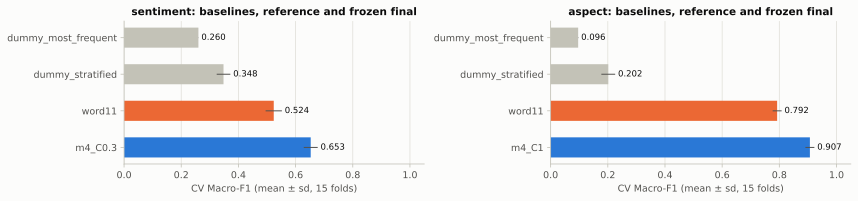

In [32]:
models = wt.fit_final_models(dev, rebuilt)
final_models = {task: models[task]["final"] for task in experiments.TASKS}
wt.plot_cv_summary(rebuilt);

<div dir="rtl">

## 11. تحليل الأخطاء (Error Analysis): على التطوير فقط

تنبؤات خارج الطية (out-of-fold) للإعدادين النهائيين في التكرار الأول: كل مراجعة تطوير يتنبأ بها نموذج لم يرها. أخطاء الاختبار تُوصف في القسم 12 من التقرير المحفوظ، ولم يتغير بعدها أي نموذج أو عتبة أو خاصية.

</div>

In [33]:
oof = {task: experiments.oof_predictions(spec, dev, task) for task, spec in frozen["final"].items()}
wt.per_class_tables(oof)

sentiment: out-of-fold Macro-F1 0.6506, accuracy 0.7711, errors 507 of 2215
aspect: out-of-fold Macro-F1 0.9048, accuracy 0.9020, errors 217 of 2215


precision  recall     f1  support
task      label                                       
sentiment ايجابي         0.899   0.827  0.861     1417
          سلبي           0.675   0.761  0.716      595
          محايد          0.346   0.409  0.375      203
aspect    المأكولات      0.913   0.902  0.907      336
          المشروبات      0.937   0.907  0.922      702
          الخدمة         0.826   0.906  0.864      512
          الجلسات        0.900   0.883  0.892      410
          الاسعار        0.971   0.910  0.939      255

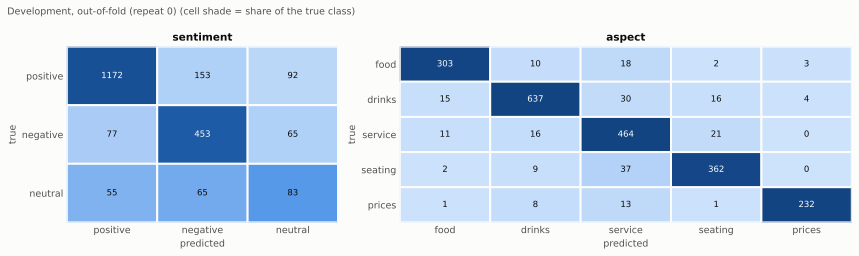

In [34]:
wt.plot_confusions({task: experiments.confusion(o, experiments.LABELS[task]) for task, o in oof.items()},
                   "Development, out-of-fold (repeat 0)");

<div dir="rtl">

**القراءة:**
- **المشاعر:** المحايد أضعف فئة بفارق كبير (F1 = 0.375)، وأخطاؤه موزعة على الطرفين. أكثر الالتباس من الإيجابي إلى السلبي، وهذا متسق مع موازنة الأوزان التي ترفع استدعاء الفئات النادرة على حساب دقة الإيجابي، وإن لم يُعزل أثرها هنا بمقارنة مع نموذج غير موزون.
- **الجانب:** الأداء متقارب بين الفئات (0.86–0.94). الخدمة تجذب أخطاء الفئات الأخرى (دقتها 0.83 مع استدعاء 0.91)، وأكبر التباس هو الجلسات ← الخدمة. التفسير المرجح أن مراجعات المكان تذكر كثيرًا الزحام أو التعامل، و«زحمه» من أكثر عبارات الخدمة تمييزًا في التحليل الاستكشافي.

### 11.1 تصنيف يدوي لعينة من الأخطاء

قُرئت عينة عشوائية ببذرة ثابتة من أخطاء خارج الطية (45 للمشاعر و30 للجانب)، وأُسندت كل منها إلى فئة سبب رئيسية (`reports/error_categories.csv`). هذه أحكام بالقراءة لا قياسات، والعينات صغيرة. البوابة المعلنة مسبقًا لتجربة تمثيل أعمق (متجهات جمل مدربة مسبقًا): أن تكون فئة «تنوع لفظي لا تلتقطه n-grams» الأكبر، وأن تبلغ 30% على الأقل.

</div>

sentiment: lexical variety 22% of 45 errors, the largest category -> gate stays closed
aspect: lexical variety 30% of 30 errors, not the largest category -> gate stays closed


reviews            share       
task                                                sentiment aspect sentiment aspect
lexical or semantic variety not captured by n-grams        10      9      0.22    0.3
several aspects / mixed polarity in one text                9     12      0.20    0.4
borderline neutral                                          6      0      0.13    0.0
dialect or irregular spelling                               5      0      0.11    0.0
label noise (gold label looks wrong or debatable)           5      6      0.11    0.2
negation                                                    4      0      0.09    0.0
sarcasm or implicit opinion                                 4      0      0.09    0.0
too short or uninformative                                  1      3      0.02    0.1
other                                                       1      0      0.02    0.0

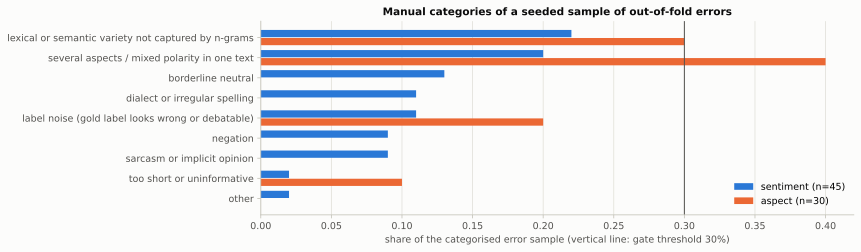

In [35]:
categories = wt.error_categories()
display(categories)
wt.plot_error_categories(categories);

<div dir="rtl">

**القراءة:** البوابة بقيت مغلقة في المهمتين. في المشاعر التنوع اللفظي الأكبر لكنه 22% فقط، وفي الجانب 30% لكنه ليس الأكبر. لذلك لم يُستخدم Deep Learning: الدليل لم يقل إن التمثيل هو عنق الزجاجة. في الجانب أكبر فئة «عدة جوانب في نص واحد» (40%)، وهي حد في الوسوم نفسها لا في النموذج، و20% من عينة الجانب بدا وسمها خاطئًا أو قابلًا للنقاش. (عينة الجانب سُحبت من أخطاء الإعداد C = 3 قبل إضافة فحص التعقيد، وكما يوضح `reports/error_analysis.md` تخص البوابة التمثيلَ الذي يتشاركه الإعدادان.)

### 11.2 أمثلة قصيرة من الأخطاء

</div>

In [36]:
for task in experiments.TASKS:
    print(task)
    display(wt.error_examples(oof[task], dev))

sentiment


,rid,gold,predicted,text
0,2122,ايجابي,سلبي,انا من محبين القهوة وبصراحه دانكن مذاقها غير
1,947,ايجابي,محايد,المعروف لايعرف مشروبات ساخنه او بارده ممتازه
2,436,سلبي,محايد,اسعار عاليه بس للكشخة و الموضة
3,1920,ايجابي,سلبي,الكفي يتميز- أسعاره غير مرتفعة …


aspect


,rid,gold,predicted,text
0,993,المشروبات,الخدمة,كل يوم لازم اخذ منه
1,2585,الجلسات,الخدمة,ممتاز ولكن يفتقد الى الانترنت والتلفزيون
2,1160,المشروبات,الجلسات,أحد أفضل المقاهي في منطقة عرقة.⏎منطقة إعداد ة ونظيفة. …
3,1053,المشروبات,الجلسات,مقهى معروف


<div dir="rtl">

**القراءة:** «غير» من أقوى خصائص السلبي، فيخطئ النموذج حين تأتي في سياق إيجابي: «مذاقها غير» بمعنى مميز في اللهجة، أو نفي لصفة سلبية «غير مرتفعة». النفي يُلتقط عبر n-grams فقط، ووسمه الصريح لم يجتز قاعدة القبول. وأخطاء الجانب في نصوص لا تسمّي جانبًا صريحًا («مقهى معروف»، «كل يوم لازم اخذ منه»)، أو تصف المكان ووسمها المشروبات، وهذا إما ذكر لأكثر من جانب أو ضوضاء وسوم.

### 11.3 ماذا يرى النموذج؟

أعلى الخصائص وزنًا لكل فئة في النموذجين النهائيين («» تعني مقطع أحرف، و· حدّ الكلمة داخله):

</div>

In [37]:
for task, pipeline in final_models.items():
    display(wt.top_features(pipeline))

,top 8 features
ايجابي,مكان ممتاز رائع قهوة احلى «مي» جميل قهوه
سلبي,سيئ مبالغ غير سيء ولا «·سي» اقل غالي
محايد,بس جيد عادي ولكن لكن مزدحم لاكن مقبول


,top 8 features
الاسعار,«سع» «سعا» «سعار» «عار» «سعر» «اسعا» «سعار·» «عار·»
الجلسات,«مك» «مكا» «مكان» «مكان·» «جل» «جلس» «كان·» «كان»
الخدمة,«خد» «خدم» «دم» «·خد» «·خدم» «امل» «مة·» «عامل»
المأكولات,«دو» «نات» «ونا» «ونات» «دونا» «دونات» «دون» «نات·»
المشروبات,«قه» «قهو» «هو» «·قه» «·قهو» «لقه» «لقهو» «قهوة»


<div dir="rtl">

**القراءة:** الخصائص معقولة لغويًا وقابلة للتفسير. المشاعر: ممتاز ورائع وجميل للإيجابي؛ سيئ ومبالغ وغالي و«غير» للسلبي؛ بس وعادي ولكن ومقبول للمحايد، وهي العبارات الاستدراكية نفسها التي ظهرت في التحليل الاستكشافي. الجانب: مقاطع «سعر/اسعار» و«مكان/جلس» و«خدم» و«دونات» و«قهو» تجمع كل الأشكال الكتابية للكلمة، وهذا متسق مع تفوق `char25` في الجانب.

</div>

<div dir="rtl">

## 12. النتائج النهائية: الاختبار المحجوز (من التقارير المحفوظة فقط)

قُرئ الاختبار مرة واحدة بالأمر `python -m arabic_reviews final` في 2026-10-25، بعد أن تحقق الإجراء من بصمة البروتوكول المجمّد. النماذج دُرّبت على التطوير كله (2215 مراجعة)، وفواصل الثقة 95% بطريقة bootstrap (2000 إعادة معاينة، وحدة المعاينة مجموعة شبه المكررات). **لا يُعاد هنا أي حساب على الاختبار**: كل ما يلي من `reports/final_test.json`، بعد التحقق من أنه ينتمي إلى البروتوكول نفسه الذي أُعيد بناؤه في القسم 10.

</div>

In [38]:
result = wt.final_test_report(rebuilt)
wt.heldout_model_table(result, rebuilt)

✓ saved test results come from the frozen protocol — reports/final_test.json, fingerprint ec20dc6ba8170319…
✓ saved test results come from the one logged test read — run 1, 2026-10-25T10:29:29+00:00, commit b577bb0


configuration  macro_f1           ci_95  balanced_accuracy  accuracy
task      model                                                                                            
sentiment final                       m4_logreg_C0.3    0.6564  [0.604, 0.704]             0.6704    0.7635
          reference                    logreg_word11    0.5547  [0.507, 0.605]             0.5502    0.7870
          dummy (most frequent)  dummy_most_frequent    0.2599  [0.249, 0.270]             0.3333    0.6390
          dummy (stratified)        dummy_stratified    0.3052  [0.276, 0.336]             0.3078    0.4892
aspect    final                         m4_logreg_C1    0.9009  [0.873, 0.925]             0.8967    0.9007
          reference                    logreg_word11    0.8252  [0.789, 0.858]             0.8058    0.8321
          dummy (most frequent)  dummy_most_frequent    0.0969  [0.086, 0.107]             0.2000    0.3195
          dummy (stratified)        dummy_stratified    0.2131  [0.179, 0.247]             0.2138    0.2329

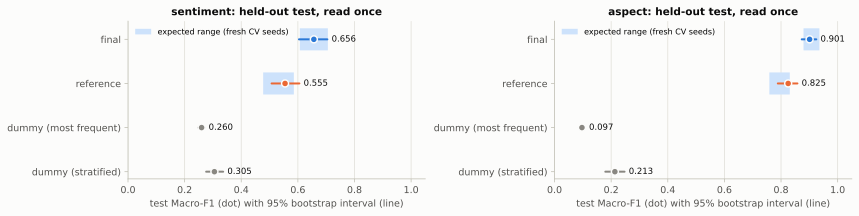

In [39]:
wt.plot_test_results(result, rebuilt);

<div dir="rtl">

**القراءة:** المشاعر Macro-F1 = 0.656 [0.604, 0.704]، والجانب 0.901 [0.873, 0.925]. كلتاهما داخل المدى المتوقع المحسوب قبل الاختبار، فالنتيجة متسقة مع تقديرات التطوير ولا تُظهر تفاؤلًا واضحًا فيها.

**دقة المشاعر 0.764 أقل من دقة المرجع 0.787، رغم تفوق Macro-F1.** التفسير المرجح، من اتجاه CV لا من تجربة عزل على الاختبار، أن موازنة الأوزان تنقل جزءًا من التنبؤات نحو السلبي والمحايد النادرين. هذا يرفع Macro-F1، الهدف المعلن، على حساب الدقة الكلية التي تهيمن عليها فئة الإيجابي.

**المقارنات المزدوجة والقرار بالقاعدة المجمّدة:**

</div>

In [40]:
wt.paired_table(result)

observed           ci_95  share_le_0 decision task_success
task      final_minus                                                                      
sentiment reference                0.1017  [0.044, 0.162]       0.001    above          yes
          dummy (most frequent)    0.3965  [0.342, 0.447]       0.000    beats          yes
          dummy (stratified)       0.3512  [0.290, 0.411]       0.000    beats          yes
aspect    reference                0.0757  [0.047, 0.105]       0.000    above          yes
          dummy (most frequent)    0.8041  [0.775, 0.830]       0.000    beats          yes
          dummy (stratified)       0.6878  [0.647, 0.727]       0.000    beats          yes

<div dir="rtl">

**القراءة:** الفرق عن المرجع +0.102 للمشاعر و+0.076 للجانب، وفاصلا الثقة لا يشملان الصفر. التفوق على نموذجَي Dummy كبير. القرار وفق القاعدة المعلنة قبل الاختبار: **نجاح في المهمتين**.

### 12.1 الفئات ومصفوفات الالتباس على الاختبار

</div>

precision  recall     f1           ci_95  test_rows note
task      label                                                              
sentiment ايجابي         0.873   0.797  0.833  [0.799, 0.863]        354     
          سلبي           0.674   0.811  0.736  [0.681, 0.788]        148     
          محايد          0.396   0.404  0.400  [0.274, 0.517]         52     
aspect    المأكولات      0.960   0.867  0.911  [0.859, 0.952]         83     
          المشروبات      0.954   0.932  0.943  [0.915, 0.966]        177     
          الخدمة         0.814   0.898  0.854  [0.808, 0.895]        127     
          الجلسات        0.856   0.864  0.860  [0.804, 0.906]        103     
          الاسعار        0.952   0.922  0.937  [0.883, 0.976]         64

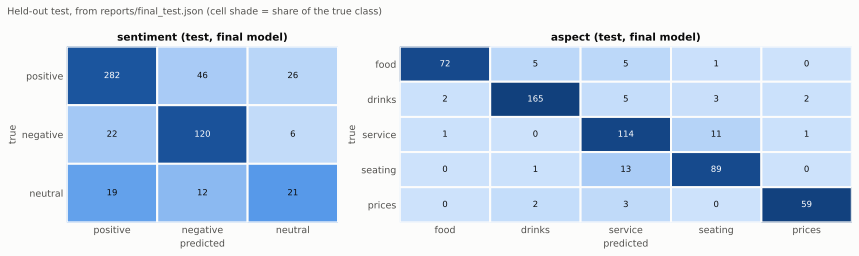

In [41]:
display(wt.heldout_per_class(result))
wt.plot_confusions(wt.heldout_confusions(result), "Held-out test, from reports/final_test.json");

<div dir="rtl">

**القراءة:** الصورة تطابق تحليل أخطاء التطوير: المحايد أضعف فئة (F1 = 0.400، بفاصل واسع [0.274, 0.517] لأنه 52 مراجعة فقط)، والخدمة والجلسات أكثر ما يختلط ببعضه في الجانب (13 + 11 خطأً من 55).

### 12.2 مستويات اليقين على الاختبار

</div>

test_rows  test_share  test_accuracy  fresh_seed_share  fresh_seed_accuracy
task      level                                                                              
sentiment high          202       0.365          0.946             0.352                0.937
          medium        156       0.282          0.756             0.270                0.817
          low           196       0.354          0.582             0.378                0.593
aspect    high          408       0.736          0.978             0.713                0.981
          medium         84       0.152          0.786             0.181                0.812
          low            62       0.112          0.548             0.106                0.548

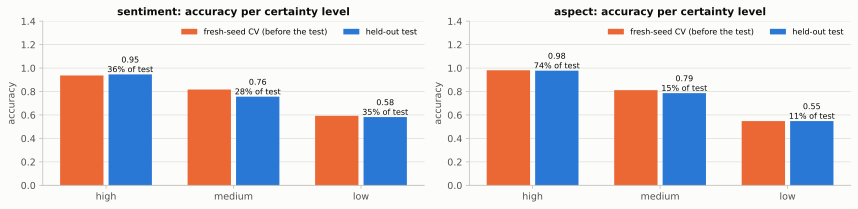

In [42]:
levels = wt.heldout_levels(result, rebuilt)
display(levels)
wt.plot_levels(levels);

<div dir="rtl">

**القراءة:** العتبات مجمّدة من التطوير، وصمدت على الاختبار. «عالٍ» أصاب 94.6% في المشاعر (36.5% من المراجعات) و97.8% في الجانب (73.6%)، و«منخفض» نحو 55–58% في المهمتين. المستوى إذن إشارة فرز مرصودة على هذه البيانات: المراجعات ذات اليقين المنخفض أحق بالمراجعة البشرية. لكنه ليس احتمالًا معايَرًا، ولم يُقس على بيانات من مصدر آخر.

### 12.3 الوسمان معًا

</div>

In [43]:
wt.joint_cells(result)

joint accuracy (both labels right): 0.6986; expected range [0.665, 0.746] -> inside


n  joint_accuracy                   note
aspect    sentiment                                            
المأكولات ايجابي      62           0.823                       
          سلبي        11           0.364  too small for a claim
          محايد       10           0.300  too small for a claim
المشروبات ايجابي     137           0.803                       
          سلبي        27           0.519                       
          محايد       13           0.231  too small for a claim
الخدمة    ايجابي      54           0.574                       
          سلبي        59           0.898                       
          محايد       14           0.286  too small for a claim
الجلسات   ايجابي      73           0.795                       
          سلبي        21           0.381                       
          محايد        9           0.667  too small for a claim
الاسعار   ايجابي      28           0.536                       
          سلبي        30           0.833                       
          محايد        6           0.333  too small for a claim

<div dir="rtl">

**القراءة:** التطابق المشترك 0.699، داخل المدى المتوقع [0.665, 0.746]. الخلايا الأقل من 20 مراجعة مُعلَّمة ولا يُبنى عليها حكم (القاعدة ثابتة قبل الاختبار).

### 12.4 الاستدلال على مراجعات جديدة

النموذجان النهائيان المدربان في القسم 10.3 (بصمتهما مطابقة للمقيَّمين) على نصوص جديدة مصاغة للتوضيح، عبر `predict.predict`. هذه هي الدالة التي تستدعيها الواجهة، بفحوص المدخلات نفسها وكلمات اليقين نفسها:

</div>

In [44]:
wt.predict_examples(final_models, [
    "الخدمة بطيئة والموظف ما رد علينا",
    "القهوة لذيذة والمكان هادي",
    "الأسعار مبالغ فيها مقارنة بالكمية",
    "الحلى عادي ما فيه شي مميز",
    "great coffee",
])

,review,aspect,aspect_certainty,sentiment,sentiment_certainty,note
0,الخدمة بطيئة والموظف ما رد علينا,الخدمة,عالٍ,سلبي,عالٍ,
1,القهوة لذيذة والمكان هادي,المشروبات,عالٍ,ايجابي,عالٍ,
2,الأسعار مبالغ فيها مقارنة بالكمية,الاسعار,عالٍ,سلبي,عالٍ,
3,الحلى عادي ما فيه شي مميز,المأكولات,منخفض,محايد,منخفض,runner-up aspect: الاسعار; sentiment: سلبي
4,great coffee,—,—,—,—,refused: not_arabic


<div dir="rtl">

**القراءة:** المراجعات الواضحة تأتي بيقين عالٍ. المراجعة الفاترة («عادي») تأتي بيقين منخفض مع الوسم الثاني، وهي من نوع الحالات الحدية التي يضعف فيها النموذج. النص غير العربي يُرفض قبل النموذج. والمراجعة الثانية تذكر جانبين (القهوة والمكان)، فيعطي النموذج جانبًا واحدًا كما تفرض الوسوم.

### 12.5 الخلاصة والحدود

**ما تحقق:** نموذجان خطيان اقتصاديان وقابلان للتفسير (TF-IDF + Logistic Regression) يعملان على CPU عادي. يتفوقان بوضوح على خطوط الأساس في اختبار محجوز قُرئ مرة واحدة: المشاعر 0.656 والجانب 0.901 Macro-F1، وكلتاهما داخل المدى المتوقع. وكل قرار نمذجة بعد التقسيم (الخصائص والنموذج والعتبات) اتُّخذ بقاعدة معلنة مسبقًا على التطوير وحده. أما قواعد إصلاح البيانات وتجميع شبه المكررات فصُممت على الملف كله قبل التقسيم، واختيرت عتبات التجميع بقراءة أزواج مع وسومها، كما يوثق `reports/split.md`.

**الحدود:**
- **جانب واحد لكل مراجعة:** نحو 10% من المراجعات تذكر أكثر من جانب، وهذه أكبر فئة في عينة أخطاء الجانب.
- **المحايد ضعيف** (F1 = 0.40): فئة صغيرة حدودها غير حادة، وجزء من أخطائها ضوضاء وسوم.
- **النفي يُلتقط عبر n-grams فقط**، فقد تخطئ العبارات المنفية غير الشائعة أو تأتي بيقين منخفض.
- **النطاق:** مقاهي الرياض على Google Maps؛ التعميم على مطاعم أو لهجات أخرى غير مقيس. مستويات اليقين نطاقات لدرجة النموذج على هذا التوزيع، لا احتمالات معايَرة.

**سجل الفحوص في هذا التشغيل.** سجل الوصول يُفحص مرة أخيرة: ما زال يحوي قراءة واحدة بعد تشغيل الدفتر كله.

</div>

In [45]:
wt.access_log_table()
wt.checks_table()

✓ the held-out test was read exactly once — 1 entry in reports/test_access_log.json


,check,result,detail
0,"published data manifest, validation and split reports unchanged",pass,byte-identical
1,source file matches the published fingerprint,pass,10.5281/zenodo.17781916
2,validation reconciles,pass,3000 = 2769 kept + 231 excluded
3,validation steps equal the published lineage,pass,reports/lineage.json
4,validated data byte-identical to the published hash,pass,SHA-256 66b938be391f…
5,split rebuilt from the validated data equals the published split,pass,data/splits/split_v1.csv
6,near-duplicate pairs equal the published list,pass,176 pairs
7,leakage checks are all zero,pass,14 counts
8,the development data is exactly the published development partition,pass,"2215 rows: rid, group and CV folds equal to data/splits/split_v1.csv"
9,the held-out test was read exactly once,pass,1 entry in reports/test_access_log.json
